# Stages 1 to 5: Problem Definition, Data Acquisition, Preparation, Preprocessing & Balancing

---

# Stage 1: Problem Definition & Use Case Specification

## 1.1 Real-World Problem Context
Phishing attacks remain one of the most prolific, destructive cyber threats worldwide. Attackers engineer deceptive uniform resource locators (URLs) to impersonate trusted institutions—such as commercial banks, cloud services, and e-commerce platforms—manipulating victims into divulging sensitive credentials, financial data, and personal information.

Traditional defenses like static domain blacklists suffer from critical latency: new phishing domains are registered, weaponized, and discarded within hours, often well before blacklists update. Consequently, **pre-execution, real-time statistical detection of phishing URLs** represents a vital first-line cyber defense.

## 1.2 Stakeholders & Intended Users
- **End-Users & Web Browsers:** Everyday internet users seeking instant validation of links in emails, SMS, or web pages before navigation.
- **Enterprise Security Operations Centers (SOC):** Analysts triaging reported phishing incidents and filtering suspicious web telemetry.
- **Email Gateway & DNS Providers:** Automated security pipelines requiring lightweight, high-throughput URL filtering.

## 1.3 Project Objective & Expected Impact
The primary goal of **PhishGuard** is to engineer an ultra-low-latency, zero-scraping machine learning security system that:
1. Evaluates raw URL strings deterministically without remote HTTP/DOM fetching.
2. Accurately flags malicious URLs while minimizing false alarms on legitimate subpages.
3. Provides transparent, auditable feature-level risk explanations to users.

## 1.4 System Inputs & Outputs
- **Input:** A raw URL string submitted through the user interface (e.g., `https://secure-login.bank-update.com/verify?account=123`).
- **Output:**
  - Binary classification: **Phishing** (`is_phishing = 1`) or **Legitimate** (`is_phishing = 0`).
  - Calibrated model probability and risk tier (Safe, Low Risk, Medium Risk, High Risk).
  - Interpretable structural breakdown highlighting key risk indicators.

## 1.5 System Constraints & Operational Guardrails
1. **Permitted Algorithms:** Strictly restricted to **Logistic Regression** and **Decision Tree Classifier** per project specifications.
2. **Zero Remote Web Fetching:** The system must evaluate the URL in sub-millisecond time. No remote DNS queries, web page scraping, or DOM parsing are permitted at inference time.
3. **Safety Disclaimer:** Machine learning outputs represent probabilistic risk assessments, not absolute security guarantees.

## 1.6 Target Mapping & Asymmetric Cost Matrix
- **Raw Dataset Target (`label`):** `0` = Phishing, `1` = Legitimate.
- **Project Canonical Target (`is_phishing`):**
  $$\text{is\_phishing} = (\text{label} == 0).\text{astype}(\text{int8})$$
  - `is_phishing = 1`: **Phishing** (Positive Security Class)
  - `is_phishing = 0`: **Legitimate** (Negative Security Class)

### Cost Breakdown of Classification Errors:
- **False Negative (FN) [CRITICAL COST]:** Predicting a phishing URL as Legitimate. The user visits the malicious website, resulting in credential theft, financial loss, or malware compromise.
- **False Positive (FP) [MODERATE COST]:** Predicting a legitimate URL as Phishing. The user experiences friction or warning dialogs.
- **Optimization Strategy:** Maximize **Phishing Recall** and **PR-AUC / F1-Score** to aggressively curtail False Negatives while using threshold calibration to safeguard against unnecessary false alarms.


In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Add project root to sys.path
sys.path.append("..")
from src.config import RAW_DATA_PATH, RAW_DATA_ENCODING, RAW_TARGET_COL, DERIVED_TARGET_COL

# Set visualization aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'

# Load raw dataset using robust latin1 encoding
df_raw = pd.read_csv(RAW_DATA_PATH, encoding=RAW_DATA_ENCODING)
df = df_raw.copy()
df[DERIVED_TARGET_COL] = (df[RAW_TARGET_COL] == 0).astype("int8")

print(f"Total Raw Observations: {len(df):,}")
print(f"Total Columns: {df.shape[1]}")

# Target class distribution table
target_counts = df[DERIVED_TARGET_COL].value_counts()
target_pcts = df[DERIVED_TARGET_COL].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    "Class Name": ["Legitimate (is_phishing=0)", "Phishing (is_phishing=1)"],
    "Raw Label": [1, 0],
    "Derived Target": [0, 1],
    "Sample Count": [target_counts[0], target_counts[1]],
    "Proportion": [f"{target_pcts[0]:.2f}%", f"{target_pcts[1]:.2f}%"]
})
print("\nTarget Mapping & Class Balance Summary:")
print(summary_df.to_string(index=False))


Total Raw Observations: 30,000
Total Columns: 57

Target Mapping & Class Balance Summary:
                Class Name  Raw Label  Derived Target  Sample Count Proportion
Legitimate (is_phishing=0)          1               0         17157     57.19%
  Phishing (is_phishing=1)          0               1         12843     42.81%


---

# Stage 2: Data Acquisition & Understanding

## 2.1 Dataset Source, Provenance & Ownership
- **Dataset Name:** PhiUSIIL Phishing URL Dataset (30,000-sample balanced benchmark subset).
- **Authors & Citation:** Arvind Prasad & Shalini Chandra (2023), *PhiUSIIL: A diverse and comprehensive dataset for phishing URL detection*, **Cybersecurity (Springer)**, 6(1), 1-19.
- **Repository:** UCI Machine Learning Repository (Dataset ID: 967).
- **Licensing:** Creative Commons Attribution 4.0 International (CC BY 4.0).
- **Workspace File:** `PhiUSIIL_Phishing_30000.csv` (7,542,406 bytes).

## 2.2 Dataset Dimensions & Structural Overview
- **Total Records:** 30,000 samples.
- **Total Attributes:** 56 columns (55 predictors + 1 raw target).
- **Missing Values:** Exactly 0 missing/null cells across the entire matrix.
- **Primary Identifier:** `FILENAME` (30,000 unique string keys).
- **Raw URL Column:** `URL` (29,989 unique URLs, 11 duplicate URLs).

## 2.3 Six-Tier Feature Taxonomy
The 56 dataset attributes span six distinct logical categories:
1. **Identifier (1):** `FILENAME` (collection artifact file ID).
2. **Raw Text Strings (4):** `URL`, `Domain`, `TLD`, `Title`.
3. **Deployable URL Structural & Lexical Metrics (18) [FS-URL]:**
   `URLLength`, `DomainLength`, `IsDomainIP`, `TLDLength`, `NoOfSubDomain`, `HasObfuscation`, `NoOfObfuscatedChar`, `ObfuscationRatio`, `NoOfLettersInURL`, `LetterRatioInURL`, `NoOfDegitsInURL`, `DegitRatioInURL`, `NoOfEqualsInURL`, `NoOfQMarkInURL`, `NoOfAmpersandInURL`, `NoOfOtherSpecialCharsInURL`, `SpacialCharRatioInURL`, `IsHTTPS`.
4. **URL Statistical Probabilities (4):** `URLSimilarityIndex`, `CharContinuationRate`, `TLDLegitimateProb`, `URLCharProb`.
5. **Page Content / HTML / DOM Features (28) [FS-REF]:**
   `LineOfCode`, `LargestLineLength`, `HasTitle`, `DomainTitleMatchScore`, `URLTitleMatchScore`, `HasFavicon`, `Robots`, `IsResponsive`, `NoOfURLRedirect`, `NoOfSelfRedirect`, `HasDescription`, `NoOfPopup`, `NoOfiFrame`, `HasExternalFormSubmit`, `HasSocialNet`, `HasSubmitButton`, `HasHiddenFields`, `HasPasswordField`, `Bank`, `Pay`, `Crypto`, `HasCopyrightInfo`, `NoOfImage`, `NoOfCSS`, `NoOfJS`, `NoOfSelfRef`, `NoOfEmptyRef`, `NoOfExternalRef`.
6. **Target Column (1):** `label` (`0` = Phishing, `1` = Legitimate).

## 2.4 Limitations of the Dataset
1. **Homepage Sampling Bias for Legitimate Sites:** In the PhiUSIIL dataset, 100% of legitimate URLs are clean root domain homepages with lengths $\le 51$ characters and `www.` prefixes. In contrast, phishing URLs feature deep paths and parameters.
2. **Collection Artifacts in Identifiers:** As revealed in Stage 4, the `FILENAME` attribute contains collection prefixes that leak ground truth labels.


In [2]:
# Feature Type & Attribute Profiling
dtypes_count = df.dtypes.value_counts()
print("Attribute Data Types Distribution:")
for dtype, count in dtypes_count.items():
    print(f"  - {str(dtype):<10}: {count} columns")

print(f"\nTotal Missing Values across all 56 columns: {df.isnull().sum().sum()}")
print(f"Unique FILENAME count: {df['FILENAME'].nunique():,} (Matches row count: {df['FILENAME'].nunique() == len(df)})")
print(f"Unique URL count:      {df['URL'].nunique():,} ({len(df) - df['URL'].nunique()} duplicates)")

# Preview sample rows across feature tiers
sample_cols = ['FILENAME', 'URL', 'URLLength', 'IsDomainIP', 'IsHTTPS', 'LineOfCode', 'label']
print("\nSample Records Across Key Feature Tiers:")
print(df[sample_cols].head(4).to_string(index=False))


Attribute Data Types Distribution:
  - int64     : 41 columns
  - float64   : 10 columns
  - object    : 5 columns
  - int8      : 1 columns

Total Missing Values across all 56 columns: 0
Unique FILENAME count: 30,000 (Matches row count: True)
Unique URL count:      29,989 (11 duplicates)

Sample Records Across Key Feature Tiers:
    FILENAME                                  URL  URLLength  IsDomainIP  IsHTTPS  LineOfCode  label
  683936.txt https://www.westannouncements.com.au         35           0        1       11716      1
 mw29982.txt          http://www.f0585194.xsph.ru         26           0        0           9      0
mw204791.txt            http://www.buthagnere.com         24           0        0           2      0
 8137531.txt      http://1353290755.hyperphp.com/         31           0        0           2      0


---

# Stage 3: Data Preparation

## 3.1 Data Preparation Objectives
Data preparation ensures the raw data is cleaned, validated, verified for logical boundary consistency, and formatted for reproducible model training without data loss.

## 3.2 Duplicate Record Analysis & Resolution
- **Complete Row Duplicates:** Exactly 0 rows are complete 56-feature duplicates.
- **Identifier Duplicates:** Exactly 0 duplicate `FILENAME` records exist (30,000 unique records).
- **URL Duplicates Inspection:**
  - 11 unique URLs appear twice (22 records total).
  - **Label Consistency Audit:** All 11 duplicate URL pairs have **100% identical labels** (`label = 0` / Phishing for all 11 pairs). There are zero conflicting URL labels.
- **Domain Repetition:** 1,063 unique domains appear multiple times (1,311 records total). Only 1 domain (`www.mod.gov.in`) has URLs with differing scheme/labels (`http://...` vs `https://...`), which is valid behavior because encryption (`IsHTTPS`) differentiates security posture.

## 3.3 Text Encoding Handling
The raw CSV contains non-ASCII characters in the `Title` column (e.g. byte `0xfd`). Explicit `latin1` decoding prevents `UnicodeDecodeError` across all Python environments.

## 3.4 Value Boundary Integrity Checks
- **Target (`label`):** Strictly bounded to $\{0, 1\}$.
- **Binary Features (17 columns):** Strictly bounded to $\{0, 1\}$.
- **Count Features (19 columns):** Zero negative values observed ($x \ge 0$).


In [3]:
from src.data_validation import audit_data_quality

# Run centralized data quality audit
audit_results = audit_data_quality(df_raw)

print("=== DATA QUALITY AUDIT RESULTS ===")
for k, v in audit_results.items():
    print(f"  {k:<32}: {v}")

# Inspect the 11 duplicate URLs and their label consistency
url_counts = df['URL'].value_counts()
dup_urls = url_counts[url_counts > 1].index.tolist()

print(f"\nInspecting Duplicate URLs ({len(dup_urls)} unique URLs appearing {len(dup_urls)*2} times):")
dup_df = df[df['URL'].isin(dup_urls)][['URL', 'label', DERIVED_TARGET_COL]].sort_values('URL')
print(dup_df.head(6).to_string(index=False))

# Verify zero label conflicts
label_variance = df[df['URL'].isin(dup_urls)].groupby('URL')[DERIVED_TARGET_COL].nunique()
print(f"Conflicting duplicate URL labels: {(label_variance > 1).sum()} (Zero conflicts confirmed)")


=== DATA QUALITY AUDIT RESULTS ===
  total_rows                      : 30000
  total_columns                   : 56
  missing_values_count            : 0
  complete_duplicate_rows         : 0
  duplicate_filenames             : 0
  duplicate_urls                  : 11
  conflicting_url_labels_count    : 0
  unique_raw_labels               : [0, 1]
  labels_valid                    : True
  invalid_binary_columns          : {}

Inspecting Duplicate URLs (11 unique URLs appearing 22 times):
                                                            URL  label  is_phishing
http://595221.selcdn.ru/qwerty-ohdhdjejnnad-najahhy/index4.html      0            1
http://595221.selcdn.ru/qwerty-ohdhdjejnnad-najahhy/index4.html      0            1
                                 http://www.universalonline.com      0            1
                                 http://www.universalonline.com      0            1
       https://1e7d9d0a-42c5-4f1b-8565-60011f15534d.id.repl.co/      0            1
  

---

# Stage 4: Data Preprocessing & Leakage Audit

## 4.1 Missing Value Treatment
The dataset contains **0 missing values** across all 30,000 samples $	imes$ 56 columns. No imputation is necessary.

## 4.2 Data Leakage Audit (`FILENAME` Artifact Discovery)
During forensic audit of the dataset attributes, a critical data leakage vulnerability was discovered in `FILENAME`:
- Samples with prefix `mw` (4,681 records) $\to$ **100% Phishing** (`is_phishing = 1`).
- Samples with prefix `op` (1,168 records) $\to$ **100% Phishing** (`is_phishing = 1`).
- Samples with numeric prefixes (e.g., `10...` to `99...`, 24,151 records) $\to$ **100% Legitimate** (`is_phishing = 0`).

**Mandatory Preprocessing Action:**
`FILENAME` is an explicit target proxy resulting from data collection artifacts (e.g., *Malware* and *OpenPhish* collection folders). It is placed in `EXCLUDED_FEATURES` and **strictly excluded from all model training and feature sets**.

Similarly, raw text strings (`URL`, `Domain`, `TLD`, `Title`) cannot be fed as raw text into numerical models and are excluded from the predictor matrix.

## 4.3 Outlier Analysis & Preservation Rationale
- `URLLength` spans from 13 to 4,274 characters ($Q3 + 1.5 \times IQR = 53.5$). 2,893 records (9.64%) exceed this bound.
- `NoOfDegitsInURL` spans from 0 to 1,912 digits. 6,490 records (21.63%) exceed the standard IQR bound.
- **Outlier Preservation Decision:** **Do NOT remove or truncate extreme observations.** Extreme URL lengths and dense digit sequences represent authentic cyberattack obfuscation mechanisms (e.g. token injection, hex encoding, subfolder chaining). Truncating them would corrupt genuine phishing signals.

## 4.4 Feature Transformation & Scaling Architecture
- **Continuous Numerical Features (15):** Scaled using `StandardScaler` to ensure zero-mean and unit-variance.
- **Binary Categorical Features (3):** Retained unscaled (`passthrough`) to maintain $\{0, 1\}$ boolean interpretability.
- **Pipeline Encapsulation:** Scalers are wrapped inside `sklearn.compose.ColumnTransformer` and `sklearn.pipeline.Pipeline`, guaranteeing that fitting occurs **strictly on training folds** during cross-validation.


In [4]:
from src.preprocessing import EXCLUDED_FEATURES, get_feature_preprocessor
from src.feature_extraction import FS_URL_NUMERIC, FS_URL_BINARY

# 1. Forensic proof of FILENAME leakage
df['filename_prefix'] = df['FILENAME'].astype(str).str.extract(r'^([a-zA-Z]+|\d+)')
prefix_breakdown = df.groupby('filename_prefix')[DERIVED_TARGET_COL].agg(
    count='count',
    phishing_rate='mean'
).reset_index()

prefix_breakdown['phishing_pct'] = (prefix_breakdown['phishing_rate'] * 100).round(2).astype(str) + '%'
print("=== FILENAME LEAKAGE AUDIT TABLE ===")
print(prefix_breakdown.to_string(index=False))

# 2. Outlier Analysis on Continuous Features
outlier_stats = []
for col in ['URLLength', 'DomainLength', 'NoOfDegitsInURL', 'SpacialCharRatioInURL']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    outliers = (df[col] > upper_bound).sum()
    outlier_stats.append({
        'Feature': col,
        'Min': df[col].min(),
        'Q1 (25%)': round(q1, 2),
        'Median (50%)': round(df[col].median(), 2),
        'Q3 (75%)': round(q3, 2),
        'Max': df[col].max(),
        'IQR Bound': round(upper_bound, 2),
        'Outlier Count': outliers,
        'Outlier %': f"{outliers / len(df) * 100:.2f}%"
    })

print("\n=== CONTINUOUS FEATURE OUTLIER ANALYSIS ===")
print(pd.DataFrame(outlier_stats).to_string(index=False))

print(f"\nConfirmed EXCLUDED_FEATURES (Zero-Leakage Enforcement):\n{EXCLUDED_FEATURES}")


=== FILENAME LEAKAGE AUDIT TABLE ===
filename_prefix  count  phishing_rate phishing_pct
         100041      1            0.0         0.0%
         100045      1            0.0         0.0%
         100053      1            0.0         0.0%
         100061      1            0.0         0.0%
         100090      1            0.0         0.0%
         100120      1            0.0         0.0%
         100153      1            0.0         0.0%
         100169      1            0.0         0.0%
         100178      1            0.0         0.0%
         100199      1            0.0         0.0%
         100203      1            0.0         0.0%
         100241      1            0.0         0.0%
         100330      1            0.0         0.0%
         100343      1            0.0         0.0%
         100347      1            0.0         0.0%
         100368      1            0.0         0.0%
         100381      1            0.0         0.0%
         100404      1            0.0        

---

# Stage 5: Data Balancing Analysis

## 5.1 Class Distribution Assessment
- **Legitimate (`is_phishing = 0`):** 17,157 samples (**57.19%**)
- **Phishing (`is_phishing = 1`):** 12,843 samples (**42.81%**)
- **Imbalance Ratio:** $\frac{17,157}{12,843} = 1.336 : 1$

The dataset is naturally balanced, with both classes extensively represented in tens of thousands of authentic instances.

## 5.2 Critical Evaluation of Balancing Techniques
1. **Random Undersampling (RUS):** Discarding ~4,300 legitimate URLs to achieve exact 50/50 balance would needlessly discard valid domain patterns and reduce model statistical power.
2. **SMOTE (Synthetic Minority Over-sampling):**
   - Synthesizing artificial samples in discrete structural spaces (such as URL character counts, subdomain counts, and binary flags) creates unrealistic fractional observations (e.g., 1.4 subdomains or 0.3 IP flags).
   - Furthermore, performing SMOTE before splitting risks severe cross-split synthetic data leakage.
3. **Selected Engineering Strategy:**
   - Retain the natural 57/43 empirical class distribution.
   - Address class-sensitive costs through algorithmic hyperparameter tuning:
     - Evaluate `class_weight='balanced'` vs `None` in Logistic Regression and Decision Tree models.
     - Calibrate the decision threshold ($T = 0.65$) on validation splits to control precision/recall trade-offs without distorting the underlying feature space.


Class Imbalance Ratio (Legitimate / Phishing): 1.336 : 1
Status for Stage 5: Naturally balanced distribution validated. No synthetic resampling needed.


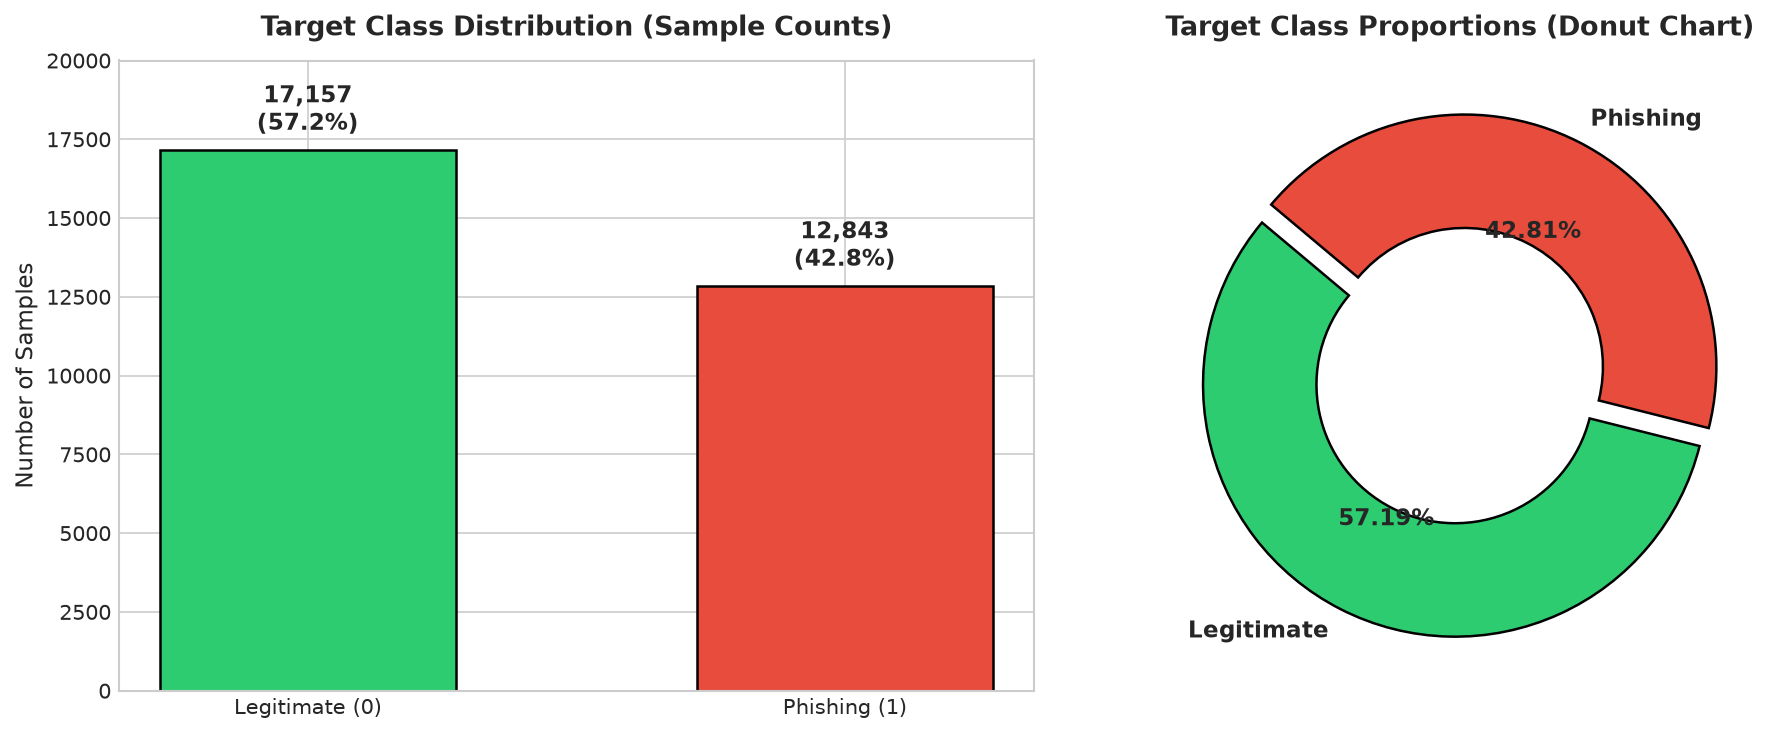

In [5]:
# Visualizing Class Balance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Count Bar Plot
colors = ['#2ecc71', '#e74c3c']
bars = ax1.bar(['Legitimate (0)', 'Phishing (1)'], [target_counts[0], target_counts[1]], color=colors, width=0.55, edgecolor='black', linewidth=1.2)
ax1.set_title("Target Class Distribution (Sample Counts)", fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel("Number of Samples", fontsize=11)
ax1.set_ylim(0, 20000)

for bar in bars:
    height = bar.get_height()
    ax1.annotate(f"{height:,}\n({height/len(df)*100:.1f}%)",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 6), textcoords="offset points",
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

# Subplot 2: Donut Chart
wedges, texts, autotexts = ax2.pie(
    [target_counts[0], target_counts[1]],
    labels=['Legitimate', 'Phishing'],
    autopct='%1.2f%%',
    startangle=140,
    colors=colors,
    explode=(0.04, 0.04),
    wedgeprops=dict(width=0.45, edgecolor='black', linewidth=1.2),
    textprops=dict(fontsize=11, fontweight='bold')
)
ax2.set_title("Target Class Proportions (Donut Chart)", fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

print(f"Class Imbalance Ratio (Legitimate / Phishing): {target_counts[0] / target_counts[1]:.3f} : 1")
print("Status for Stage 5: Naturally balanced distribution validated. No synthetic resampling needed.")
